# Statistical Analysis

## Project Objective

Evaluate statistical relationships between customer characteristics,
financial variables, and term deposit subscription outcomes.

This notebook examines hypothesis testing, confidence intervals,
and differences in financial characteristics.

In [2]:
# Import libraries for data analysis and statistical testing.
import pandas as pd
import matplotlib.pyplot as plt

from scipy import stats

df = pd.read_csv("../data/raw/bank-full.csv", sep = ";")

# Verify the dataset dimensions.
df.shape

(45211, 17)

In [3]:
# Create a contingency table for housing loans and subscriptions.

housing_table = pd.crosstab(df["housing"], df["y"])

housing_table

y,no,yes
housing,,
no,16727,3354
yes,23195,1935


In [4]:
# Perform a chi-square test of independece.

chi2, p_value, dof, expected = stats.chi2_contingency(housing_table)

#Display the test results. 
print("Chi-square statistic:", chi2)
print("P-value:", p_value)
print("Degrees of freedom", dof)

Chi-square statistic: 874.822448867983
P-value: 2.918797605076633e-192
Degrees of freedom 1


In [5]:
# Create a contingency table for personal loans and subscriptions

loan_table = pd.crosstab(df["loan"], df["y"])

loan_table

y,no,yes
loan,,
no,33162,4805
yes,6760,484


In [6]:
# Perform a chi-square tets for personal loans

loan_chi2, loan_p_value, loan_dof, loan_expected = stats.chi2_contingency(loan_table)

#Display the test results
print("Chi-sqaure statistic", loan_chi2)
print("P-value:", loan_p_value)
print("Degrees of freedom", loan_dof)

Chi-sqaure statistic 209.61698034978633
P-value: 1.6650611634927562e-47
Degrees of freedom 1


In [9]:
from statsmodels.stats.proportion import proportion_confint

# Calculate the subscription rate and the confidence interval

subscribed = 4805
total_customers = 37967

subscription_rate = subscribed / total_customers

lower, upper = proportion_confint(
    count = subscribed,
    nobs = total_customers,
    alpha = 0.05,
    method = "wilson"
)

print(f"Subscription rate: {subscription_rate:.2%}")
print(f"955 Condidence Interval: {lower:.2%} to {upper:.2%}")

Subscription rate: 12.66%
955 Condidence Interval: 12.33% to 12.99%


In [13]:
 # Seperate account balances by subscription outcome.

subscribed_balances = df[df["y"] == "yes"]["balance"]
not_subscribed_balances = df[df["y"] == "no"]["balance"]

# Calculate median account balances for each group

print("Median balance (susbcribed):", subscribed_balances.median())
print("Median balance(not subscribed):", not_subscribed_balances.median())

# Perform the Mann-Whitney U test

u_stat, balance_p_value = stats.mannwhitneyu(
    subscribed_balances,
    not_subscribed_balances,
    alternative = "two-sided"
)

print("Mann-Whitney U statistic:", u_stat)
print("P-value:", balance_p_value)

#Calculate subscription rates by loan status

housing_rates = df.groupby("housing")["y"].apply(
    lambda x: (x=="yes").mean() * 100
)
personal_loan_rates = df.groupby("loan")["y"].apply(
    lambda x: (x=="yes").mean() * 100
)
print("Housing loan subscription rates:")
print(housing_rates)

print("\nPersonal loan subscription rates:")
print((personal_loan_rates))

Median balance (susbcribed): 733.0
Median balance(not subscribed): 417.0
Mann-Whitney U statistic: 124589983.5
P-value: 6.593845808689515e-101
Housing loan subscription rates:
housing
no     16.702355
yes     7.699960
Name: y, dtype: float64

Personal loan subscription rates:
loan
no     12.655727
yes     6.681391
Name: y, dtype: float64


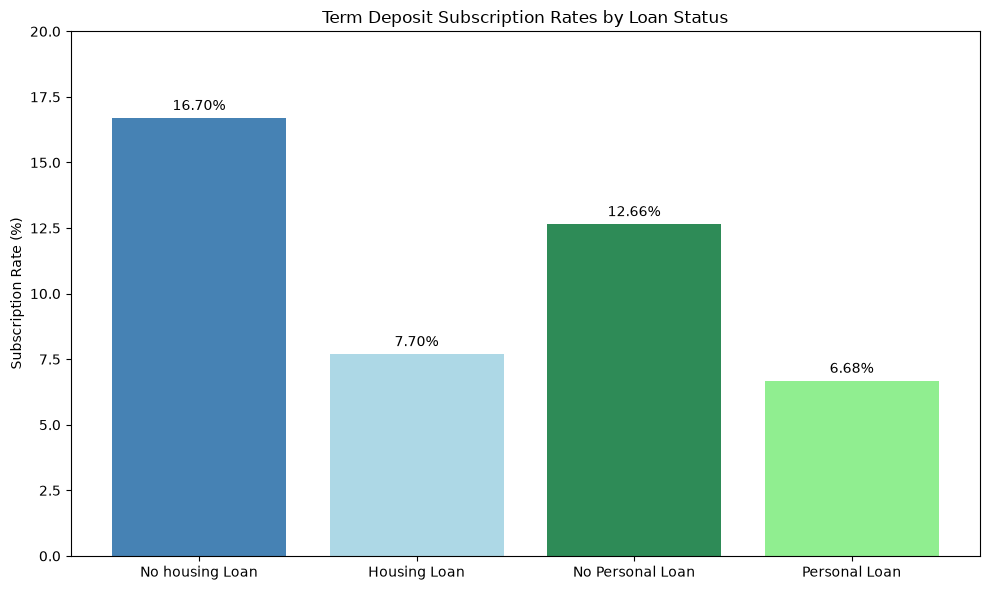

In [15]:
labels = [
    "No housing Loan",
    "Housing Loan",
    "No Personal Loan",
    "Personal Loan"
]

rates = [
    housing_rates["no"],
    housing_rates["yes"],
    personal_loan_rates["no"],
    personal_loan_rates["yes"]
]

#Create a bar chart comparing subscription rates.
plt.figure(figsize=(10,6))

bars = plt.bar(
    labels, 
    rates,
    color = ["steelblue","lightblue", "seagreen", "lightgreen"]
)

plt.title("Term Deposit Subscription Rates by Loan Status")
plt.ylabel("Subscription Rate (%)")
plt.ylim(0,20)

# Add percentage labels above each bar
for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height + 0.3,
        f"{height:.2f}%",
        ha = "center"
    )
plt.tight_layout()

#Save the chart in the existing plots folder.

plt.savefig("../plots/loan_status_subscription_rates.png", dpi = 300)

plt.show()

## Statistical Analysis — Key Findings

### 1. Housing Loan Status
Customers without housing loans had a subscription rate of 16.70%,
compared with 7.70% for customers with housing loans.

The difference suggests housing loan status may be a useful
customer segmentation variable.

### 2. Personal Loan Status
A chi-square test found a statistically significant association
between personal loan status and term deposit subscription
(p < 0.001).

Customers without personal loans had higher subscription rates
than customers with personal loans.

### 3. Confidence Interval
The subscription rate among customers without personal loans
was approximately 12.66%, with a 95% Wilson confidence interval
of 12.33% to 12.99%.

This interval quantifies uncertainty around the estimated
subscription rate under the relevant sampling assumptions.

### 4. Account Balance Comparison
Customers who subscribed had a median account balance of €733,
compared with €417 among customers who did not subscribe.

The Mann–Whitney U test indicated a statistically significant
difference in account balance distributions (p < 0.001).

### Business Implications
- Loan status and account balance may be useful features for
  customer segmentation and predictive modeling.
- Customers without existing loans demonstrated higher historical
  subscription rates.
- Statistical significance does not establish causation.
- Predictive models should be evaluated on unseen data before
  making targeting recommendations.

### Limitations
- The analysis uses historical observational data.
- Associations do not establish causal relationships.
- Statistical significance does not necessarily imply a large
  or practically useful effect.
- Results may not generalize to future marketing campaigns.
